In [3]:
import numpy as np
import datetime
import matplotlib.pyplot as plt
import pandas as pd
import keras
import bayesflow as bf

RNG = np.random.default_rng(2025)

In [4]:
import os

if "KERAS_BACKEND" not in os.environ:
    # set this to "torch", "tensorflow", or "jax"
    os.environ["KERAS_BACKEND"] = "jax"

In [6]:
def prior():
    """Generates a random draw from the joint prior."""

    lambd = RNG.uniform(0.10, 0.7)
    mu = RNG.uniform(0.05, 0.2)
    D = RNG.lognormal(mean=np.log(8), sigma=0.2)
    I0 = RNG.gamma(shape=2, scale=20)
    return {"lambd": lambd, "mu": mu, "D": D, "I0": I0}

In [7]:
def convert_params(mu, phi):
    """Helper function to convert mean/dispersion parameterization of a negative binomial to N and p,
    as expected by numpy's negative_binomial.

    See https://en.wikipedia.org/wiki/Negative_binomial_distribution#Alternative_formulations
    """

    r = phi
    var = mu + 1 / r * mu**2
    p = (var - mu) / var
    return r, 1 - p


def baseline_SIR(lambd, mu, D, I0, psi = 1.2, N = 83e6, T = 50, eps=1e-5):
    """Performs a forward simulation from the SIR model given a random draw from the prior."""
    # Extract parameters and round I0 and D
    I0 = np.ceil(I0)
    D = int(round(D))

    # Initial conditions
    S, I, R = [N - I0], [I0], [0]

    # Reported new cases
    C = [I0]

    # Simulate T-1 timesteps
    for t in range(1, T + D):
        # Calculate new cases
        I_new = lambd * (I[-1] * S[-1] / N)

        # SIR equations
        S_t = S[-1] - I_new
        I_t = np.clip(I[-1] + I_new - mu * I[-1], 0.0, N)
        R_t = np.clip(R[-1] + mu * I[-1], 0.0, N)

        # Track
        S.append(S_t)
        I.append(I_t)
        R.append(R_t)
        C.append(I_new)

    reparam = convert_params(np.clip(np.array(C[D:]), 0, N) + eps, psi)
    C_obs = RNG.negative_binomial(reparam[0], reparam[1]) # Incidence
    return dict(cases=C_obs)

In [89]:
simulator = bf.make_simulator([prior, baseline_SIR])
simulator

In [18]:
adapter = (
    bf.adapters.Adapter()
    .convert_dtype("float64", "float32")
    .as_time_series("cases")
    .concatenate(["lambd", "mu", "D", "I0"], into="inference_variables")
    .rename("cases", "summary_variables")
    .log(["inference_variables", "summary_variables"], p1=True)
)

In [20]:
class GRU(bf.networks.SummaryNetwork):
    def __init__(self, **kwargs):
        super().__init__(**kwargs)

        self.gru = keras.layers.GRU(64, dropout=0.1)
        self.summary_stats = keras.layers.Dense(8)
        
    def call(self, time_series, **kwargs):
        """Compresses time_series of shape (batch_size, T, 1) into summaries of shape (batch_size, 8)."""

        summary = self.gru(time_series, training=kwargs.get("stage") == "training")
        summary = self.summary_stats(summary)
        return summary

In [87]:
summary_net = GRU()

In [88]:
inference_net = bf.networks.CouplingFlow()

In [90]:
workflow = bf.BasicWorkflow(
    simulator=simulator,
    adapter=adapter,
    inference_network=inference_net,
    summary_network=summary_net,
    standardize=None # no need to standardize due to log-transform
)

In [91]:
history = workflow.fit_online(epochs = 100, batch_size = 64, num_batches_per_epoch = 120)

INFO:bayesflow:Fitting on dataset instance of OnlineDataset.
INFO:bayesflow:Building on a test batch.


Epoch 1/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 11s 61ms/step - loss: 6.6178
Epoch 2/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 7s 59ms/step - loss: -1.3757
Epoch 3/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 7s 57ms/step - loss: -2.7835
Epoch 4/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 7s 57ms/step - loss: -3.2735
Epoch 5/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 7s 56ms/step - loss: -3.4279
Epoch 6/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 7s 58ms/step - loss: -3.4946
Epoch 7/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 7s 60ms/step - loss: -3.6016
Epoch 8/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 7s 54ms/step - loss: -3.6648
Epoch 9/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 7s 57ms/step - loss: -3.8142
Epoch 10/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 7s 59ms/step - loss: -3.8414
Epoch 11/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 7s 58ms/step - loss: -3.9334
Epoch 12/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 7s 55ms/step - loss: -3.9860
Epoch 13/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 7s 59ms/step - loss: -4.0084
Epoch 14/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 7s 58ms/step - loss: -4.1754
Epoch 15/100
12

In [43]:
epoch_times = [
    11, 7, 7, 7, 7, 7, 7, 7, 7, 7, 
    7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 
    7, 7, 7, 7, 7, 8, 7, 7, 7, 8, 
    8, 8, 7, 7, 7, 7, 8, 7, 7, 7, 
    8, 7, 7, 7, 8, 9, 8, 7, 11, 8, 
    7, 7, 7, 7, 7, 8, 7, 7, 7, 7, 
    7, 8, 8, 9, 7, 7, 7, 7, 7, 7, 
    7, 7, 7, 7, 7, 7, 8, 7, 8, 8, 
    8, 7, 7, 7, 7, 8, 7, 8, 7, 7, 
    7, 8, 8, 7, 7, 8, 7, 8, 7, 7
]
print(np.mean(epoch_times))
print(np.percentile(epoch_times, 2.5))
print(np.percentile(epoch_times, 97.5))

7.34
7.0
9.0


In [38]:
print(summary_net.count_params())
print(inference_net.count_params())

13384
221328


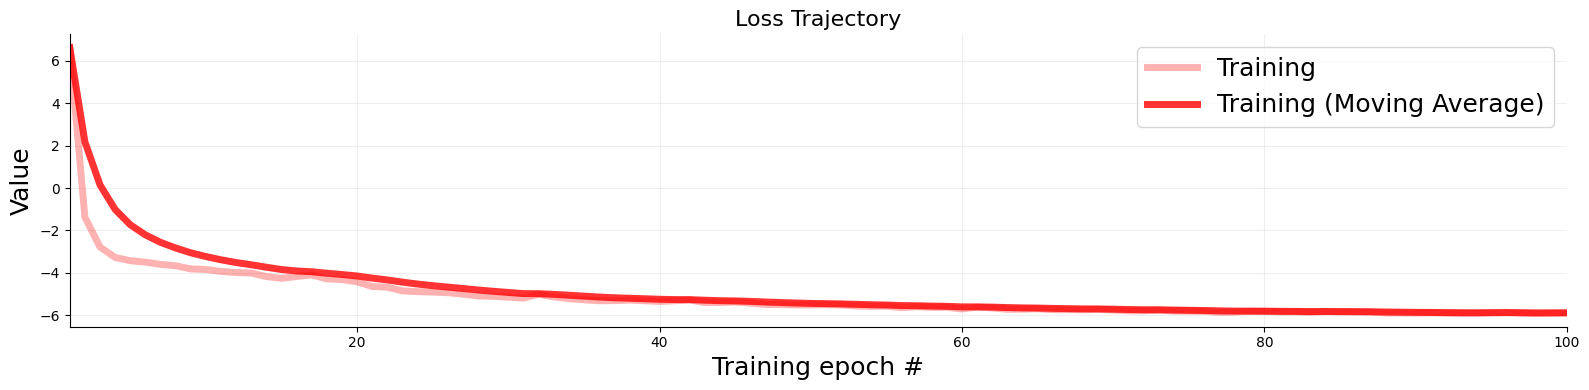

In [93]:
f = bf.diagnostics.plots.loss(history, legend_fontsize = 18, label_fontsize = 18, lw_train = 5,train_color = '#FF0000')

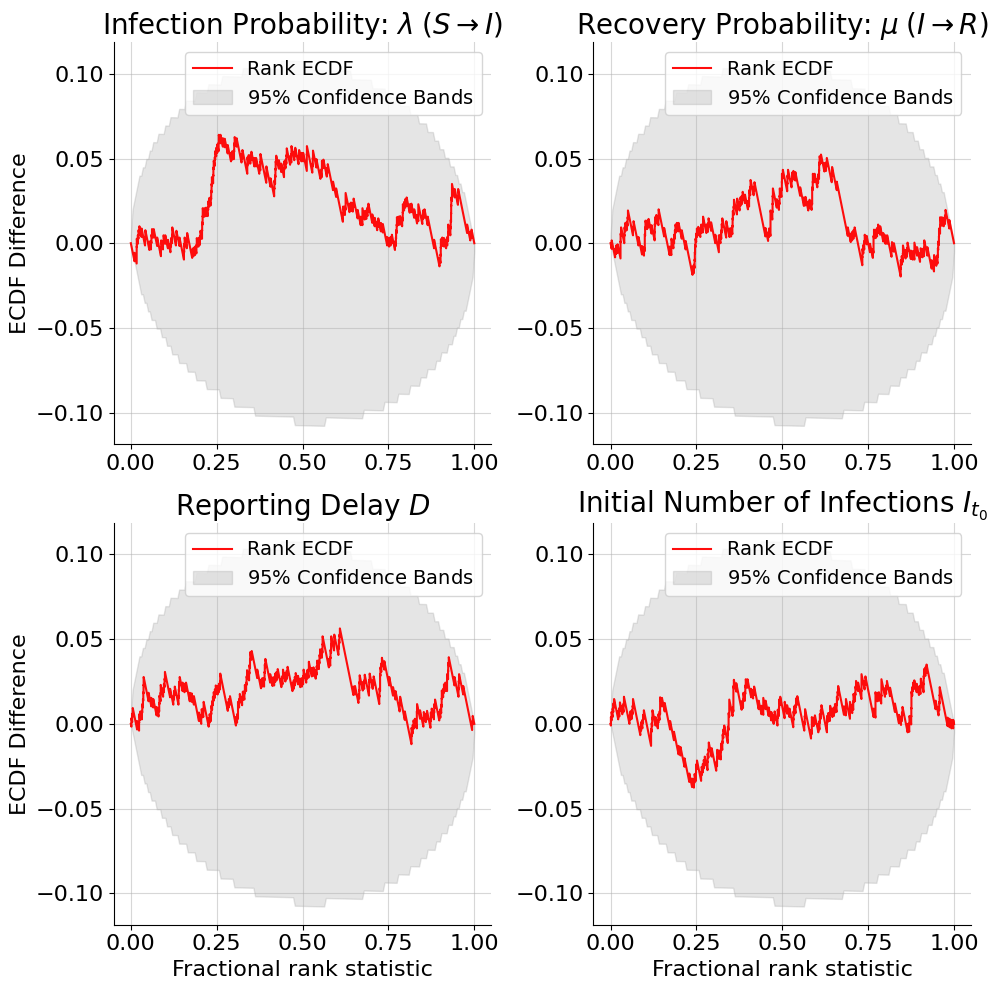

In [92]:
num_datasets = 200
test_sims = workflow.simulate(num_datasets)
samples = workflow.sample(conditions=test_sims, num_samples=3000)
f = bf.diagnostics.plots.calibration_ecdf(samples, 
                                          test_sims, 
                                          difference=True, 
                                          variable_names = [r'Infection Probability: $\lambda \; (S \rightarrow I)$', 
                                                            r'Recovery Probability: $\mu \; (I \rightarrow R)$', 
                                                            r'Reporting Delay $D$', 
                                                            r'Initial Number of Infections $I_{t_{0}}$'],
                                         tick_fontsize = 16, 
                                         title_fontsize = 20, 
                                         rank_ecdf_color = '#ff0000', 
                                         num_row = 2,
                                         num_col = 2)
plt.show()

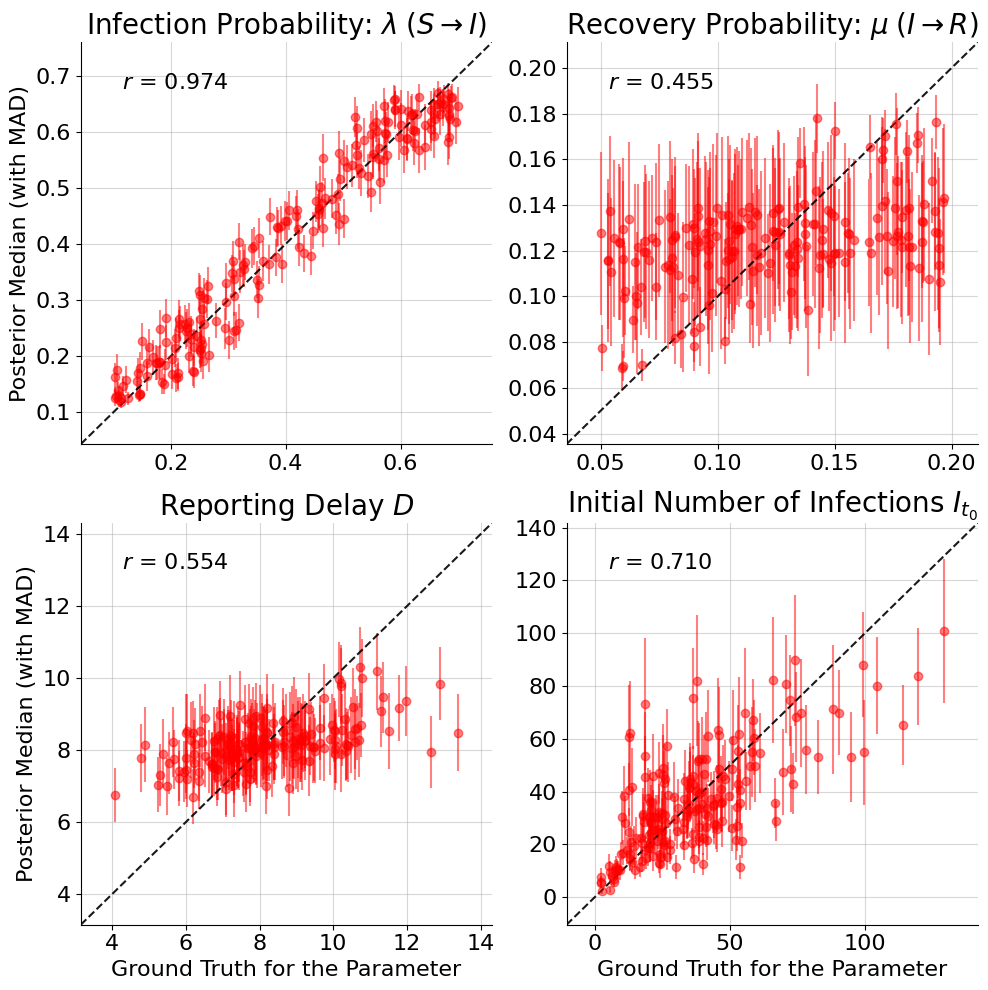

In [103]:
f = bf.diagnostics.plots.recovery(samples, 
                                  test_sims,
                                  variable_names = [r'Infection Probability: $\lambda \; (S \rightarrow I)$', 
                                                    r'Recovery Probability: $\mu \; (I \rightarrow R)$', 
                                                    r'Reporting Delay $D$', 
                                                    r'Initial Number of Infections $I_{t_{0}}$'],
                                  tick_fontsize = 16, 
                                  title_fontsize = 20, 
                                  num_row = 2,
                                  ylabel = "Posterior Median (with MAD)", 
                                  xlabel = "Ground Truth for the Parameter",
                                  num_col = 2, 
                                  color = '#ff0000')
plt.show()

In [8]:
def SIR_full(lambd, mu, D, I0, psi = 1.2, N=83e6, T=50, eps=1e-5):
    """Performs a forward simulation from the SIR model given a random draw from the prior."""
    # Extract parameters and round I0 and D
    I0 = np.ceil(I0)
    D = int(round(D))
    # Initial conditions
    S, I, R = [N - I0], [I0], [0]
    # Reported new cases
    C = [I0]
    # New recovered cases
    R_new = [0]
    # Simulate
    for t in range(1, T + D):
        # Calculate new cases
        I_new = lambd * (I[-1] * S[-1] / N)
        # Calculate new recovered
        R_new_t = mu * I[-1]
        # SIR equations
        S_t = S[-1] - I_new
        I_t = np.clip(I[-1] + I_new - R_new_t, 0.0, N)
        R_t = np.clip(R[-1] + R_new_t, 0.0, N)
        # Track
        S.append(S_t)
        I.append(I_t)
        R.append(R_t)
        C.append(I_new)
        R_new.append(R_new_t)
    
    reparam = convert_params(np.clip(np.array(C[D:]), 0, N) + eps, psi)
    C_obs = RNG.negative_binomial(reparam[0], reparam[1]) # Incidence
    
    # Also apply observation model to recoveries
    reparam_R = convert_params(np.clip(np.array(R_new[D:]), 0, N) + eps, psi)
    R_obs = RNG.negative_binomial(reparam_R[0], reparam_R[1]) # Recovered
    
    return dict(cases=C_obs, recovered=R_obs)

In [9]:
simulator_full = bf.make_simulator([prior, SIR_full])
simulator_full

In [10]:
adapter_full = (
    bf.adapters.Adapter()
    .convert_dtype("float64", "float32")
    .as_time_series(["cases", "recovered"])
    .concatenate(["lambd", "mu", "D", "I0"], into = "inference_variables")
    .concatenate(["cases", "recovered"], into = "summary_variables")
    .log(["inference_variables", "summary_variables"], p1=True)
)

In [13]:
inference_net_full = bf.networks.CouplingFlow()
summary_net_full = bf.networks.TimeSeriesNetwork()

In [14]:
workflow_full = bf.BasicWorkflow(
    simulator=simulator_full,
    adapter=adapter_full,
    inference_network=inference_net_full,
    summary_network=summary_net_full,
    standardize=None
)

In [ ]:
history_full = workflow_full.fit_online(epochs = 100, batch_size = 64, num_batches_per_epoch = 120)

INFO:bayesflow:Fitting on dataset instance of OnlineDataset.
INFO:bayesflow:Building on a test batch.


Epoch 1/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 16s 92ms/step - loss: 3.9061
Epoch 2/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 11s 93ms/step - loss: -2.5925
Epoch 3/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 13s 104ms/step - loss: -3.3748
Epoch 4/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 13s 105ms/step - loss: -3.7303
Epoch 5/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 13s 110ms/step - loss: -3.9954
Epoch 6/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 14s 114ms/step - loss: -4.0673
Epoch 7/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 12s 102ms/step - loss: -4.3017
Epoch 8/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 12s 100ms/step - loss: -4.5423
Epoch 9/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 11s 92ms/step - loss: -4.6369
Epoch 10/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 12s 99ms/step - loss: -4.7072
Epoch 11/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 13s 109ms/step - loss: -4.8659
Epoch 12/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 15s 128ms/step - loss: -4.9677
Epoch 13/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 15s 121ms/step - loss: -5.2564
Epoch 14/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 12s 103ms/step - loss: 

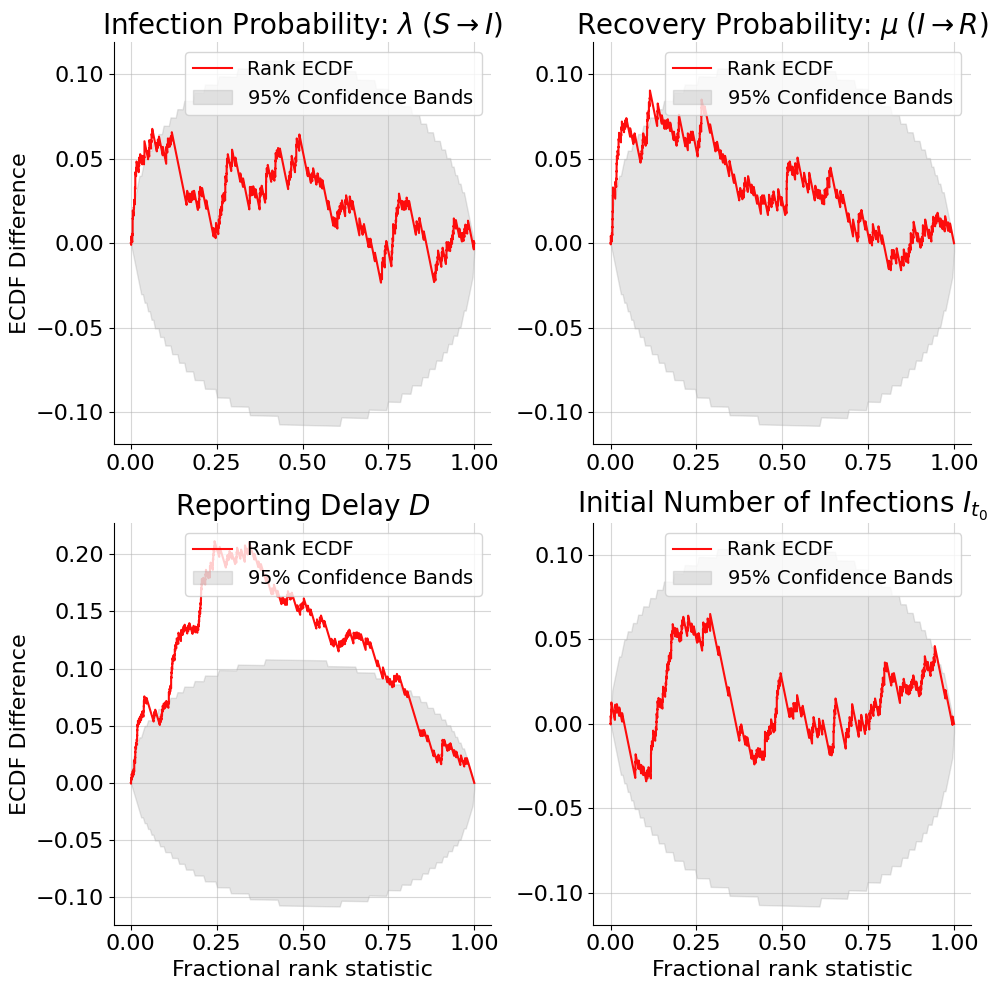

In [26]:
num_datasets = 200
test_sims_full = workflow_full.simulate(num_datasets)
samples_full = workflow_full.sample(conditions=test_sims_full, num_samples=3000)
# For each simulated dataset we have 3000 posterior samples
f_full = bf.diagnostics.plots.calibration_ecdf(samples_full, 
                                          test_sims_full, 
                                          difference=True, 
                                          variable_names = [r'Infection Probability: $\lambda \; (S \rightarrow I)$', 
                                                            r'Recovery Probability: $\mu \; (I \rightarrow R)$', 
                                                            r'Reporting Delay $D$', 
                                                            r'Initial Number of Infections $I_{t_{0}}$'],
                                         tick_fontsize = 16, 
                                         title_fontsize = 20, 
                                         rank_ecdf_color = '#ff0000', 
                                         num_row = 2,
                                         num_col = 2)
plt.show()

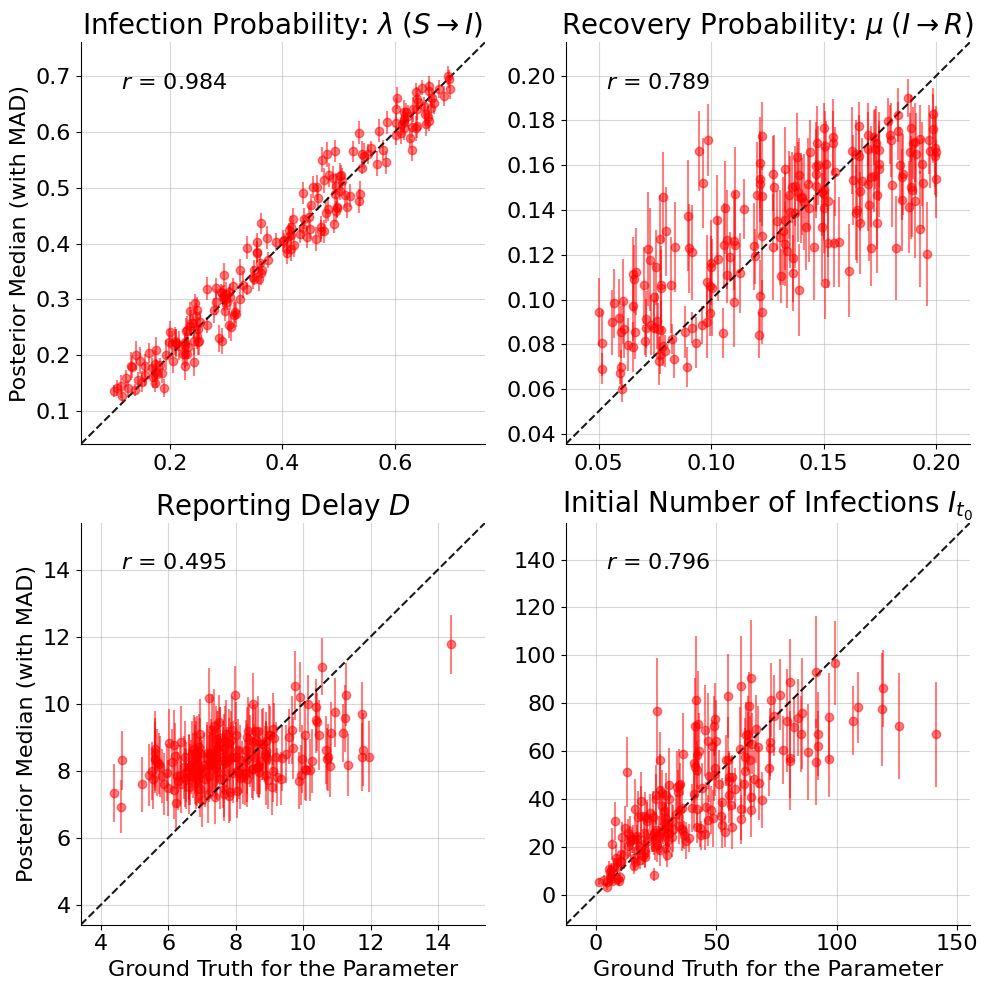

In [27]:
f = bf.diagnostics.plots.recovery(samples_full, 
                                  test_sims_full,
                                  variable_names = [r'Infection Probability: $\lambda \; (S \rightarrow I)$', 
                                                    r'Recovery Probability: $\mu \; (I \rightarrow R)$', 
                                                    r'Reporting Delay $D$', 
                                                    r'Initial Number of Infections $I_{t_{0}}$'],
                                  tick_fontsize = 16, 
                                  title_fontsize = 20, 
                                  num_row = 2,
                                  num_col = 2, 
                                  ylabel = "Posterior Median (with MAD)", 
                                  xlabel = "Ground Truth for the Parameter",
                                  color = '#ff0000')
plt.show()

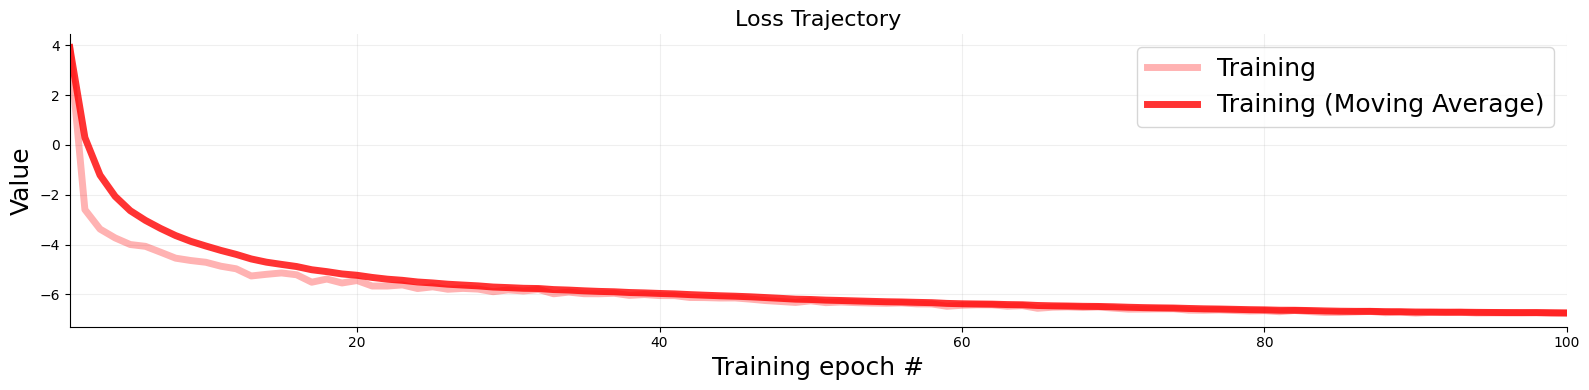

In [16]:
f = bf.diagnostics.plots.loss(history_full, legend_fontsize = 18, label_fontsize = 18, lw_train = 5,train_color = '#FF0000')